# Coding Confidence | Calibration and Selective Escalation

Can a small model predict whether a generated coding answer passes, and do probability corrections improve that estimate?

This notebook audits a fixed public-data study of 1,055 coding tasks and ten primary answers per task. It compares logistic regression, shared Platt scaling, and corrections for overlapping feature-and-score slices, with six additional baselines. The numerical archive is included: running this notebook needs no dataset downloads or model API.

The study uses existing CALIBRI/LiveCodeBench outputs and publisher labels. It was developed with AI assistance and the historical sample has already been inspected. Replaying or refitting it is a reproducibility exercise, not a new confirmatory experiment.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT = next(path for path in [Path.cwd(), *Path.cwd().parents]
               if (path / "research" / "reference.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from research.data import FEATURES
from research.methods import audit
from research.reference import load_reference
from research.reproduce import partitions_from_reference, replay_models, result_tables
from research.figures import make_figure

reference = load_reference()
parts = partitions_from_reference(reference)
frozen, protocol = reference["frozen"], reference["protocol"]
scores = replay_models(parts, frozen)
tables = result_tables(scores, parts, frozen, protocol)
frames = {name: pd.DataFrame(rows) for name, rows in tables.items()}
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
print("Reference checksums verified:", reference["manifest"]["run_id"])
print("Numerical candidate records:", len(reference["rows"]))
print("Dataset:", protocol["dataset"], "revision:", protocol["revision"])


Reference checksums verified: a8630092fa9e
Numerical candidate records: 10550
Dataset: lavis-nlp/CALIBRI revision: 7a4a7dc7aceb1b4a426c48761d0f128f2daf6a54


## Data and separation

One observation is one problem paired with one generated answer. The target is the publisher's binary benchmark outcome, not the fraction of individual test cases passed. All ten answers to a problem remain together.

Training fits feature scaling and the base model. Calibration fits Platt and the conditional offsets. Validation selects the tolerance/support configuration and routing cutoff. Test outcomes enter evaluation only. The alternate answer's label is used to evaluate escalation, never to predict the primary answer's correctness.


In [2]:
display(pd.DataFrame([
    {"partition": name, "tasks": len(np.unique(part["ids"])), "answers": len(part["y"]),
     "primary pass rate": part["y"].mean()}
    for name, part in parts.items()
]))
sets = [set(part["ids"]) for part in parts.values()]
assert all(not first.intersection(second) for j, first in enumerate(sets) for second in sets[j+1:])
print("Verified: no task crosses a partition boundary.")


,partition,tasks,answers,primary pass rate
0,train,316,3160,0.462025
1,calibration,211,2110,0.420379
2,validation,264,2640,0.447727
3,test,264,2640,0.457955


Verified: no task crosses a partition boundary.


## Sixteen measured predictors

The extractor combines size, sampled-token likelihood statistics, syntax-tree structure, and flags for invalid or missing outputs. It does not calculate full-vocabulary token entropy or cross-candidate self-consistency.

The coefficients below multiply standardized inputs and contribute to the fitted log odds. Correlated predictors make individual coefficients difficult to interpret; these values do not establish causal effects or significance. The [raw-data walkthrough](reconstruction/cursor-confidence-walkthrough.ipynb) shows exactly how the sixteen values are extracted from one real answer.


In [3]:
base = frozen["models"]["logistic"]
display(pd.DataFrame({"feature": FEATURES, "training mean": base["mean"],
                      "training scale": base["scale"], "logistic coefficient": base["coefficients"]}))


,feature,training mean,training scale,logistic coefficient
0,log_prompt_chars,7.179544,0.379332,-0.175905
1,log_code_chars,4.932393,2.919907,-0.517597
2,log_code_lines,2.399197,1.499139,-2.091595
3,log_output_tokens,6.585304,0.924368,-0.264206
4,mean_logprob,-0.119864,0.116076,-0.239882
5,p10_logprob,-0.383680,0.376589,-0.447582
6,logprob_sd,0.223839,0.134913,-1.672956
7,low_probability_fraction,0.000609,0.001629,-0.631655
8,ast_depth,6.730063,4.634240,-0.211947
9,branches,1.778165,2.663959,0.048774


## Probability quality and baselines

Brier score is mean squared probability error; log loss penalizes confident errors more strongly. Five-bin ECE summarizes prediction-versus-frequency gaps. Brier and log loss measure overall probability quality, not calibration alone. A low binned ECE is insufficient evidence that routing improves.

The baselines include isotonic calibration, a score-bin-only correction, group indicators included directly in logistic regression, token-only and structure-only models, and exponentiated mean token log probability. That last quantity is a heuristic rather than an established probability of correctness.


In [4]:
test_metrics = frames["metrics"].query("split == 'test'").set_index("method")
display(test_metrics[["brier", "log_loss", "ece", "worst", "supported_cells"]].sort_values("brier"))
display(frames["comparisons"][["method", "baseline", "estimate", "low", "high", "tasks"]])
print("Paired intervals resample 264 tasks with all sibling answers together.")


,brier,log_loss,ece,worst,supported_cells
method,,,,,
group_logistic,0.109738,0.337902,0.014245,0.153828,20
logistic,0.111126,0.340996,0.016180,0.184141,20
platt,0.111316,0.341450,0.014317,0.186146,20
score_bins,0.111316,0.341450,0.014317,0.186146,20
isotonic,0.112068,0.393181,0.019005,0.182172,20
multicalibration,0.112552,0.344726,0.020171,0.205389,21
structure_only,0.133927,0.410412,0.028141,0.208350,20
token_only,0.150889,0.463752,0.057303,0.293268,22
likelihood,0.383067,1.124068,0.428311,0.901966,11


,method,baseline,estimate,low,high,tasks
0,logistic,platt,-0.000190,-0.000799,0.000443,264
1,group_logistic,platt,-0.001578,-0.005010,0.001483,264
2,token_only,platt,0.039573,0.022090,0.055269,264
3,structure_only,platt,0.022611,0.012754,0.032671,264
4,platt,platt,0.000000,0.000000,0.000000,264
5,isotonic,platt,0.000752,-0.000426,0.001905,264
6,likelihood,platt,0.271751,0.235376,0.308398,264
7,multicalibration,platt,0.001236,-0.000818,0.003303,264
8,score_bins,platt,0.000000,0.000000,0.000000,264


Paired intervals resample 264 tasks with all sibling answers together.


Neither added calibration stage established a clear Brier improvement in the reference sample. Platt minus logistic is approximately +0.000190, with a 95% task-bootstrap interval spanning zero. Multicalibration minus Platt is approximately +0.001236, also with an interval spanning zero. Positive is worse. The group-aware baseline has a lower point estimate, but its paired interval versus Platt also spans zero.

These intervals are conditional on the fitted models. They do not account for all uncertainty from feature choices, benchmark choice, or refitting, and no simultaneous correction across the baseline comparisons is claimed.


## The conditional correction loop

The seven predefined groups include long prompts, long code, deep syntax trees, imports, empty extracted code, and one overlapping conjunction. Length and depth cutoffs use training-set quartiles. Groups are checked within five bands of the current confidence score.

A supported slice receives its mean residual, observed pass rate minus average predicted probability. After each offset, the algorithm recomputes score bands and scans again. It selects among six tolerance/support configurations by validation Brier score. It does not train a tree to invent subgroup boundaries.


In [5]:
fit = frozen["models"]["multicalibration"]
print("Selected tolerance:", fit["epsilon"], "minimum distinct tasks:", fit["support"])
print("Updates:", len(fit["patches"]), "stopping status:", fit["status"])
display(pd.DataFrame(fit["patches"])[["group", "bin", "tasks", "n", "mean", "rate", "delta"]])
audit_rows = []
for split in ("calibration", "validation", "test"):
    part = parts[split]
    cells = audit(scores[split]["multicalibration"], part["y"], part["groups"], part["ids"],
                  frozen["group_names"], protocol["bins"], fit["support"])
    supported = [cell for cell in cells if cell["supported"]]
    audit_rows.append({"partition": split, "minimum tasks": fit["support"],
                       "supported cells": len(supported),
                       "largest supported residual": max(abs(cell["residual"]) for cell in supported)})
display(pd.DataFrame(audit_rows))


Selected tolerance: 0.03 minimum distinct tasks: 40
Updates: 12 stopping status: converged_on_fit_cells


,group,bin,tasks,n,mean,rate,delta
0,long_code,2,42,138,0.501358,0.543478,0.042120
1,long_code,1,52,167,0.300449,0.335329,0.034881
2,all,1,70,193,0.315458,0.274611,-0.040847
3,long_code,2,41,134,0.497750,0.537313,0.039563
4,all,2,75,218,0.516456,0.481651,-0.034805
5,long_code,1,46,132,0.280094,0.310606,0.030512
6,all,1,69,191,0.309646,0.267016,-0.042630
7,long_code,1,45,120,0.275149,0.316667,0.041518
8,all,1,65,167,0.307901,0.269461,-0.038440
9,long_code,1,45,120,0.278226,0.316667,0.038440


,partition,minimum tasks,supported cells,largest supported residual
0,calibration,40,9,0.022090
1,validation,40,13,0.196182
2,test,40,12,0.114312


The fit stopping tolerance applies to sufficiently supported calibration cells. It does not bound held-out error. Which cells have enough distinct tasks can change across datasets and models. The earlier headline metrics use the historical audit support of 20 tasks; the table immediately above uses the selected fit support of 40, so the diagnostics answer different questions.


## Routing and selective acceptance

The default cutoff sends the lowest-confidence 30% of validation answers to their recorded alternate answers. Exact confidence ties use deterministic task/candidate keys. The test escalation fraction can differ from 30%.

Primary and alternate answers are paired by candidate index. Escalation can rescue a failure or replace a success with a failure. No live generation, repair workflow, pricing or latency measurement is involved.


In [6]:
display(test_metrics[["escalation", "success", "accepted_error", "rescued", "regressed"]])
print("Primary only:", parts["test"]["y"].mean())
print("Alternate only:", parts["test"]["alternate"].mean())
print("Default logistic, Platt and multicalibration policies have the same recorded outcomes.")
print("A shared increasing Platt transformation preserves ordering; a fixed numerical cutoff is a different policy.")


,escalation,success,accepted_error,rescued,regressed
method,,,,,
logistic,0.247727,0.511742,0.391239,0.053788,0.000000
group_logistic,0.242045,0.511742,0.395802,0.053788,0.000000
token_only,0.260985,0.496212,0.402870,0.048106,0.009848
structure_only,0.237500,0.519318,0.399404,0.061364,0.000000
platt,0.247727,0.511742,0.391239,0.053788,0.000000
isotonic,0.247348,0.523864,0.391545,0.065909,0.000000
likelihood,0.269697,0.491667,0.399896,0.046591,0.012879
multicalibration,0.247727,0.511742,0.391239,0.053788,0.000000
score_bins,0.247727,0.511742,0.391239,0.053788,0.000000


Primary only: 0.45795454545454545
Alternate only: 0.5106060606060606
Default logistic, Platt and multicalibration policies have the same recorded outcomes.
A shared increasing Platt transformation preserves ordering; a fixed numerical cutoff is a different policy.


## Diagnostics

The first panel shows paired Brier differences relative to Platt. The second compares score bands with observed pass frequencies. The third uses cutoffs learned at a grid of validation escalation budgets and evaluates them on test tasks; its horizontal axis is the resulting test acceptance fraction, not a test-selected budget.


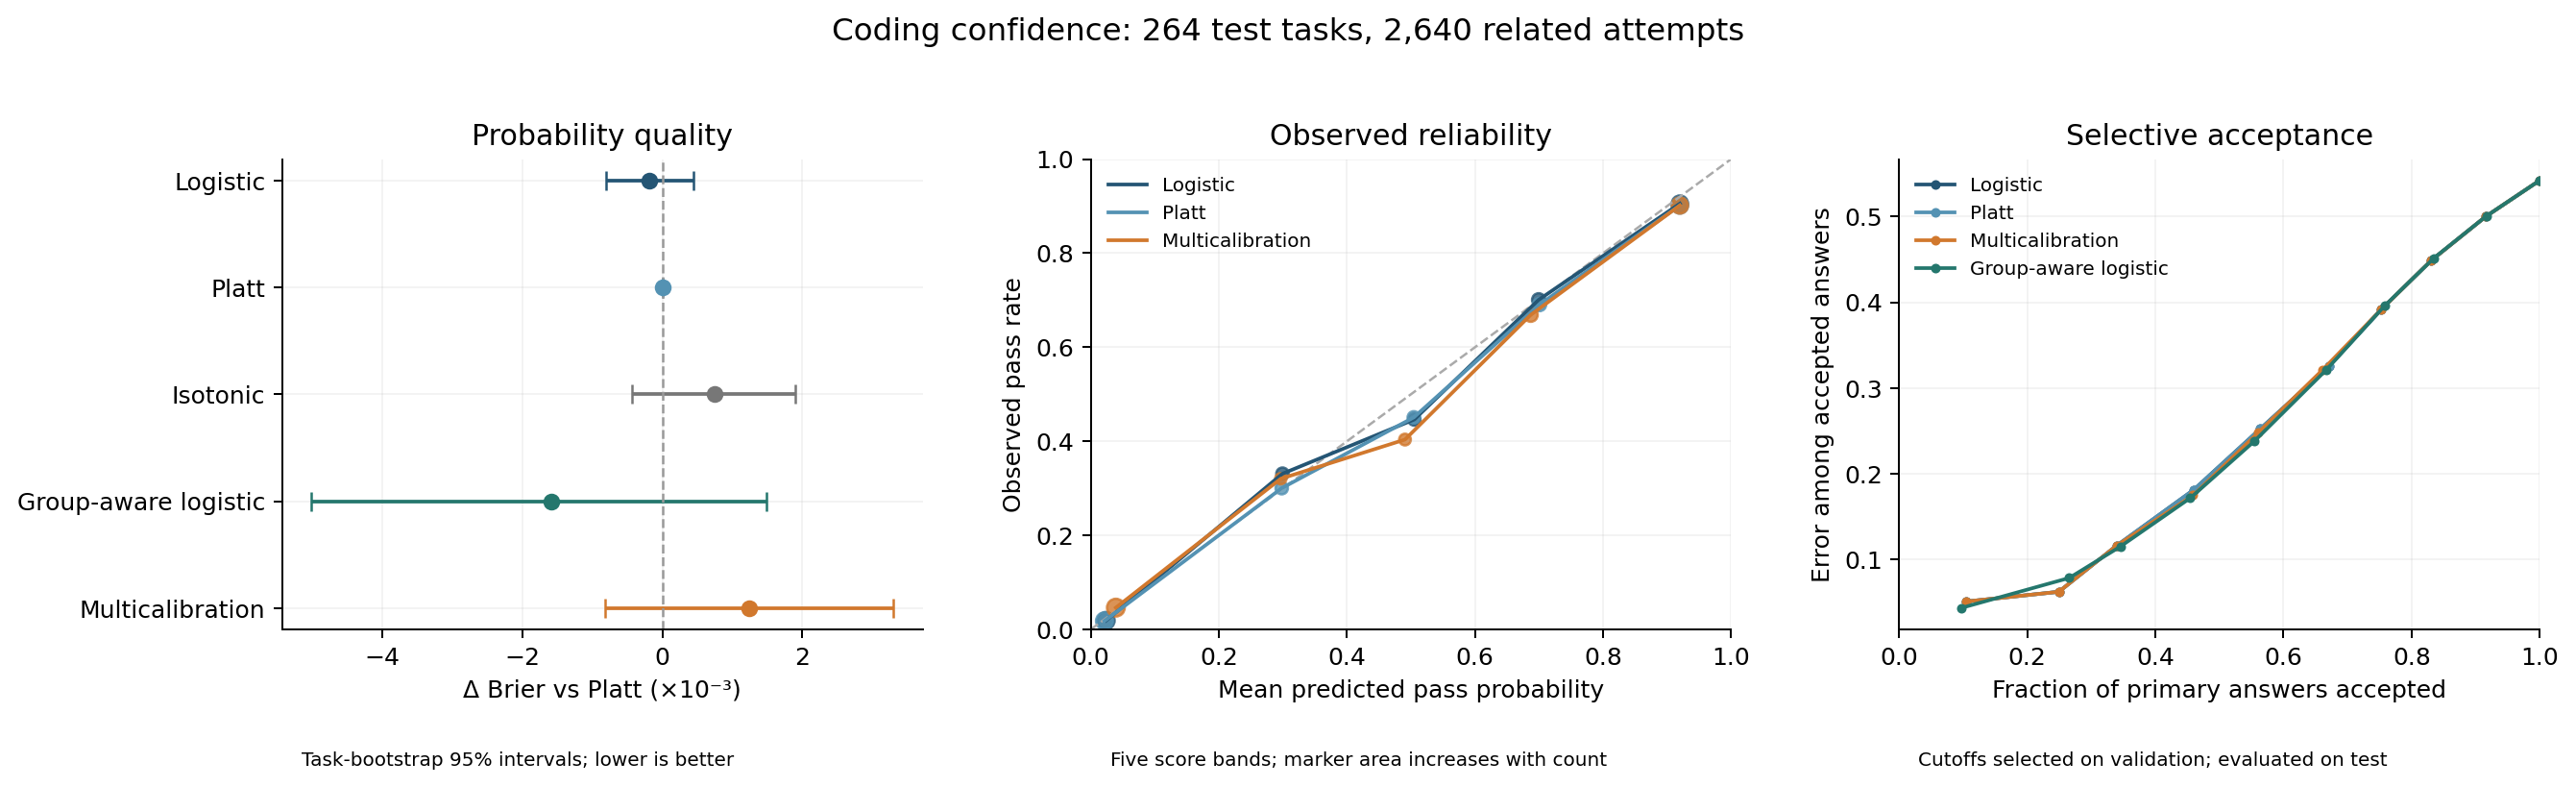

In [7]:
scratch = PROJECT / "work" / "notebook"
scratch.mkdir(parents=True, exist_ok=True)
for name, frame in frames.items():
    frame.to_csv(scratch / f"{name}.csv", index=False)
make_figure(scratch, scratch / "diagnostics.png")
display(Image(filename=str(scratch / "diagnostics.png")))


## Empty extracted programs and sensitivity

There are 612 empty extracted programs among the 2,640 test attempts. This can reflect either generation or extraction problems. A parser can identify these easy failures, so keeping them materially affects what the aggregate experiment measures.

The nonempty-only comparison is descriptive on the same inspected test data. It does not retrain or reselect a method. Its paired multicalibration-minus-Platt interval also spans zero in the reference sample.


In [8]:
subset = frames["subsets"]
display(subset.query("subset == 'nonempty'")[["method", "candidates", "tasks", "pass_rate", "brier", "estimate", "low", "high"]])


,method,candidates,tasks,pass_rate,brier,estimate,low,high
1,logistic,2028,244,0.596154,0.144660,-0.000246,-0.001027,0.000524
3,group_logistic,2028,244,0.596154,0.142854,-0.002052,-0.006564,0.001927
5,token_only,2028,244,0.596154,0.174704,0.029797,0.009244,0.048538
7,structure_only,2028,244,0.596154,0.174343,0.029436,0.015822,0.043485
9,platt,2028,244,0.596154,0.144906,0.000000,0.000000,0.000000
11,isotonic,2028,244,0.596154,0.145888,0.000981,-0.000537,0.002459
13,likelihood,2028,244,0.596154,0.314571,0.169665,0.132035,0.208762
15,multicalibration,2028,244,0.596154,0.146515,0.001609,-0.001166,0.004519
17,score_bins,2028,244,0.596154,0.144906,0.000000,0.000000,0.000000


## Reproduction and numerical precision

From the repository root:

```bash
python -m research.reproduce --output work/replay
python -m research.reproduce --refit --output work/refit
```

The first command independently replays every saved predictor, then recomputes metrics and routing. The second refits all learned stages from the included feature records using their fixed training/calibration/validation roles. Neither command re-extracts features or evaluates generated programs.

Probability comparisons use an absolute tolerance of 1e-8 and report actual maximum differences. Extremely small differences can change bins at exact boundaries: the publication check found two isotonic calibration scores moving just below 0.4 and 0.6. Its calibration-set ECE therefore differed even though the replay probabilities agreed to about 5.6e-14. Original-score diagnostics are separately verified, and every reproduction writes a metric-by-metric comparison rather than rounding scores to conceal the change.


## Scope and limits

This is one benchmark and one historical partition, with 264 independent task clusters in the test sample. Publisher outcomes and extraction were not independently rerun. Task-level splitting reduces sibling leakage, but cannot eliminate benchmark contamination or related problem families. Sample calibration does not establish population multicalibration, and the searched groups are a small predefined family.

The empirical result is a comparison of existing methods on recorded answers. It establishes no private Cursor integration, measured production savings, new calibration algorithm, or prospective validation. This expanded notebook documents the same inspected sample.

Sources: [CALIBRI](https://huggingface.co/datasets/lavis-nlp/CALIBRI), [multicalibration foundations](https://proceedings.mlr.press/v80/hebert-johnson18a.html). See [METHODS.md](METHODS.md) for definitions and [REPRODUCIBILITY.md](REPRODUCIBILITY.md) for the measured rerun record.
